# **Automatidata project**
**Course 4 - Regression Analysis: Simplify complex data relationships**

The data consulting firm Automatidata has recently hired you as the newest member of their data analytics team. Their newest client, the NYC Taxi and Limousine Commission (New York City TLC), wants the Automatidata team to build a multiple linear regression model to predict taxi fares using existing data that was collected over the course of a year. The team is getting closer to completing the project, having completed an initial plan of action, initial Python coding work, EDA, and A/B testing.

The Automatidata team has reviewed the results of the A/B testing. Now it’s time to work on predicting the taxi fare amounts. You’ve impressed your Automatidata colleagues with your hard work and attention to detail. The data team believes that you are ready to build the regression model and update the client New York City TLC about your progress.

A notebook was structured and prepared to help you in this project. Please complete the following questions.

# Course 4 End-of-course project: Build a multiple linear regression model

In this activity, you will build a multiple linear regression model. As you've learned, multiple linear regression helps you estimate the linear relationship between one continuous dependent variable and two or more independent variables. For data science professionals, this is a useful skill because it allows you to consider more than one variable against the variable you're measuring against. This opens the door for much more thorough and flexible analysis to be completed. 

Completing this activity will help you practice planning out and buidling a multiple linear regression model based on a specific business need. The structure of this activity is designed to emulate the proposals you will likely be assigned in your career as a data professional. Completing this activity will help prepare you for those career moments.
<br/>

**The purpose** of this project is to demostrate knowledge of EDA and a multiple linear regression model

**The goal** is to build a multiple linear regression model and evaluate the model
<br/>
*This activity has three parts:*

**Part 1:** EDA & Checking Model Assumptions
* What are some purposes of EDA before constructing a multiple linear regression model?

**Part 2:** Model Building and evaluation
* What resources do you find yourself using as you complete this stage?

**Part 3:** Interpreting Model Results

* What key insights emerged from your model(s)?

* What business recommendations do you propose based on the models built?

Follow the instructions and answer the questions below to complete the activity. Then, you will complete an Executive Summary using the questions listed on the PACE Strategy Document.

Be sure to complete this activity before moving on. The next course item will provide you with a completed exemplar to compare to your own work.

# Build a multiple linear regression model

<img src="images/Pace.png" width="100" height="100" align=left>

# **PACE stages**


Throughout these project notebooks, you'll see references to the problem-solving framework PACE. The following notebook components are labeled with the respective PACE stage: Plan, Analyze, Construct, and Execute.

<img src="images/Plan.png" width="100" height="100" align=left>


## PACE: **Plan**

Consider the questions in your PACE Strategy Document to reflect on the Plan stage.


### Task 1. Imports and loading
Import the packages that you've learned are needed for building linear regression models.

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from datetime import datetime
from datetime import date
from datetime import timedelta

from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler


**Note:** `Pandas` is used to load the NYC TLC dataset. As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [2]:
# Load dataset into dataframe 
df0=pd.read_csv("2017_Yellow_Taxi_Trip_Data.csv") 
df = df0.copy()

<img src="images/Analyze.png" width="100" height="100" align=left>

## PACE: **Analyze**

In this stage, consider the following question where applicable to complete your code response:

* What are some purposes of EDA before constructing a multiple linear regression model?


* **Outlier Detection & Evaluation:** Assess and handle extreme values to prevent them from disproportionately skewing model coefficients and reducing predictive accuracy.

* **Data Cleaning & Quality Control:** Identify and resolve missing values and duplicate records by deciding whether to impute or drop them.

* **Descriptive Statistics & Distribution Analysis:** Calculate summary statistics to understand data spread, central tendencies, and underlying distributions for each variable.

* **Data Formatting & Aggregation:** Verify data types, apply necessary format transformations, and aggregate features where appropriate.

* **Feature Selection:** Identify the most relevant predictor variables required to build an effective and robust multiple linear regression model

### Task 2a. Explore data with EDA

Analyze and discover data, looking for correlations, missing data, outliers, and duplicates.

Start with `.shape` and `.info()`.

In [3]:
# Start with `.shape` and `.info()`
df.shape
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             22699 non-null  int64  
 1   VendorID               22699 non-null  int64  
 2   tpep_pickup_datetime   22699 non-null  object 
 3   tpep_dropoff_datetime  22699 non-null  object 
 4   passenger_count        22699 non-null  int64  
 5   trip_distance          22699 non-null  float64
 6   RatecodeID             22699 non-null  int64  
 7   store_and_fwd_flag     22699 non-null  object 
 8   PULocationID           22699 non-null  int64  
 9   DOLocationID           22699 non-null  int64  
 10  payment_type           22699 non-null  int64  
 11  fare_amount            22699 non-null  float64
 12  extra                  22699 non-null  float64
 13  mta_tax                22699 non-null  float64
 14  tip_amount             22699 non-null  float64
 15  to

Check for missing data and duplicates using `.isna()` and `.drop_duplicates()`.

In [4]:
# Check for missing data and duplicates using .isna() and .drop_duplicates()
df.isna()
df.drop_duplicates()

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,24870114,2,03/25/2017 8:55:43 AM,03/25/2017 9:09:47 AM,6,3.34,1,N,100,231,1,13.0,0.0,0.5,2.76,0.00,0.3,16.56
1,35634249,1,04/11/2017 2:53:28 PM,04/11/2017 3:19:58 PM,1,1.80,1,N,186,43,1,16.0,0.0,0.5,4.00,0.00,0.3,20.80
2,106203690,1,12/15/2017 7:26:56 AM,12/15/2017 7:34:08 AM,1,1.00,1,N,262,236,1,6.5,0.0,0.5,1.45,0.00,0.3,8.75
3,38942136,2,05/07/2017 1:17:59 PM,05/07/2017 1:48:14 PM,1,3.70,1,N,188,97,1,20.5,0.0,0.5,6.39,0.00,0.3,27.69
4,30841670,2,04/15/2017 11:32:20 PM,04/15/2017 11:49:03 PM,1,4.37,1,N,4,112,2,16.5,0.5,0.5,0.00,0.00,0.3,17.80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22694,14873857,2,02/24/2017 5:37:23 PM,02/24/2017 5:40:39 PM,3,0.61,1,N,48,186,2,4.0,1.0,0.5,0.00,0.00,0.3,5.80
22695,66632549,2,08/06/2017 4:43:59 PM,08/06/2017 5:24:47 PM,1,16.71,2,N,132,164,1,52.0,0.0,0.5,14.64,5.76,0.3,73.20
22696,74239933,2,09/04/2017 2:54:14 PM,09/04/2017 2:58:22 PM,1,0.42,1,N,107,234,2,4.5,0.0,0.5,0.00,0.00,0.3,5.30
22697,60217333,2,07/15/2017 12:56:30 PM,07/15/2017 1:08:26 PM,1,2.36,1,N,68,144,1,10.5,0.0,0.5,1.70,0.00,0.3,13.00


Use `.describe()`.

In [5]:
# Use .describe()
df.describe()


,Unnamed: 0,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
count,2.269900e+04,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000
mean,5.675849e+07,1.556236,1.642319,2.913313,1.043394,162.412353,161.527997,1.336887,13.026629,0.333275,0.497445,1.835781,0.312542,0.299551,16.310502
std,3.274493e+07,0.496838,1.285231,3.653171,0.708391,66.633373,70.139691,0.496211,13.243791,0.463097,0.039465,2.800626,1.399212,0.015673,16.097295
min,1.212700e+04,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,-120.000000,-1.000000,-0.500000,0.000000,0.000000,-0.300000,-120.300000
25%,2.852056e+07,1.000000,1.000000,0.990000,1.000000,114.000000,112.000000,1.000000,6.500000,0.000000,0.500000,0.000000,0.000000,0.300000,8.750000
50%,5.673150e+07,2.000000,1.000000,1.610000,1.000000,162.000000,162.000000,1.000000,9.500000,0.000000,0.500000,1.350000,0.000000,0.300000,11.800000
75%,8.537452e+07,2.000000,2.000000,3.060000,1.000000,233.000000,233.000000,2.000000,14.500000,0.500000,0.500000,2.450000,0.000000,0.300000,17.800000
max,1.134863e+08,2.000000,6.000000,33.960000,99.000000,265.000000,265.000000,4.000000,999.990000,4.500000,0.500000,200.000000,19.100000,0.300000,1200.290000


### Task 2b. Convert pickup & dropoff columns to datetime


In [6]:
# Check the format of the data
df.dtypes


Unnamed: 0                 int64
VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count            int64
trip_distance            float64
RatecodeID                 int64
store_and_fwd_flag        object
PULocationID               int64
DOLocationID               int64
payment_type               int64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
dtype: object

In [7]:
# Convert datetime columns to datetime
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])


### Task 2c. Create duration column

Create a new column called `duration` that represents the total number of minutes that each taxi ride took.

In [8]:
# Create `duration` column
df['duration'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60

### Outliers

Call `df.info()` to inspect the columns and decide which ones to check for outliers.

In [9]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             22699 non-null  int64         
 1   VendorID               22699 non-null  int64         
 2   tpep_pickup_datetime   22699 non-null  datetime64[ns]
 3   tpep_dropoff_datetime  22699 non-null  datetime64[ns]
 4   passenger_count        22699 non-null  int64         
 5   trip_distance          22699 non-null  float64       
 6   RatecodeID             22699 non-null  int64         
 7   store_and_fwd_flag     22699 non-null  object        
 8   PULocationID           22699 non-null  int64         
 9   DOLocationID           22699 non-null  int64         
 10  payment_type           22699 non-null  int64         
 11  fare_amount            22699 non-null  float64       
 12  extra                  22699 non-null  float64       
 13  m

Keeping in mind that many of the features will not be used to fit your model, the most important columns to check for outliers are likely to be:
* `trip_distance`
* `fare_amount`
* `duration`



### Task 2d. Box plots

Plot a box plot for each feature: `trip_distance`, `fare_amount`, `duration`.

Text(0.5, 1.0, 'Duration')

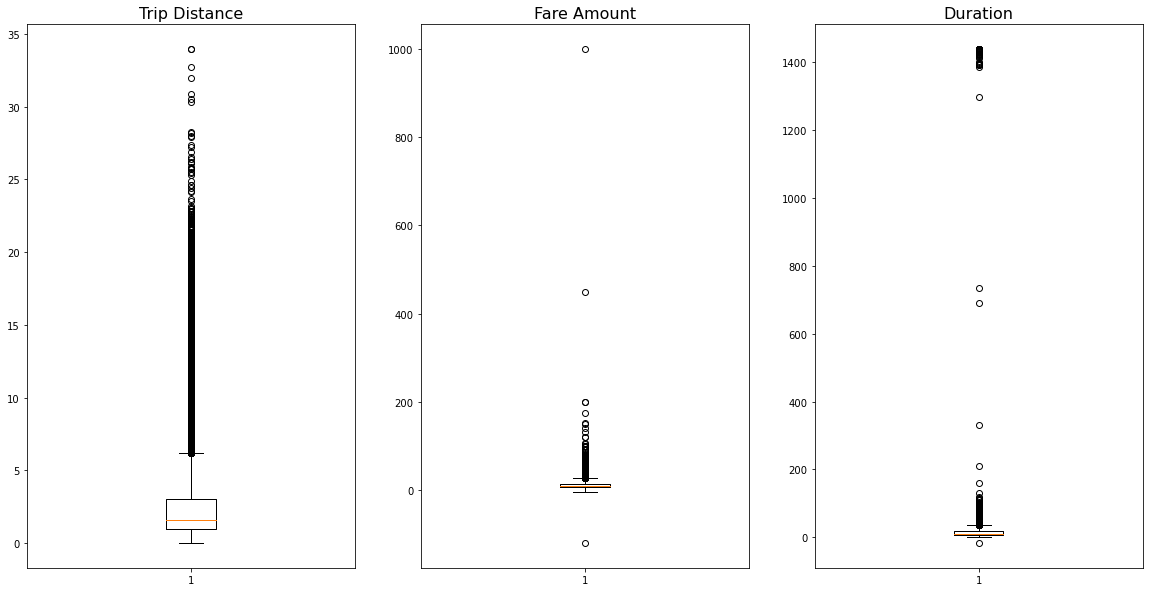

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20,10))

axes[0].boxplot(df['trip_distance'])
axes[0].set_title('Trip Distance', fontsize=16)

axes[1].boxplot(df['fare_amount'])
axes[1].set_title('Fare Amount', fontsize=16)

axes[2].boxplot(df['duration'])
axes[2].set_title('Duration', fontsize=16)


**Questions:** 
1. Which variable(s) contains outliers? 

2. Are the values in the `trip_distance` column unbelievable?

3. What about the lower end? Do distances, fares, and durations of 0 (or negative values) make sense?

* Outliers are prominently present in Fare Amount (which includes negative values and extreme upper bounds) and Duration (which exhibits negative values and unrealistically long trip times).
* The trip distance values appear reasonable and align logically with expected travel ranges; they serve as a consistent baseline that helps explain trip durations.
* Values of 0 or negative numbers for fares and durations are invalid and indicate recording errors.

### Task 2e. Imputations

#### `trip_distance` outliers

You know from the summary statistics that there are trip distances of 0. Are these reflective of erroneous data, or are they very short trips that get rounded down?

To check, sort the column values, eliminate duplicates, and inspect the least 10 values. Are they rounded values or precise values?

In [11]:
# Are trip distances of 0 bad data or very short trips rounded down?
df['trip_distance'].sort_values().drop_duplicates().head(10)


22026    0.00
5501     0.01
16827    0.02
21088    0.03
13517    0.04
10146    0.05
14373    0.06
922      0.07
22523    0.08
22035    0.09
Name: trip_distance, dtype: float64

The distances are captured with a high degree of precision. However, it might be possible for trips to have distances of zero if a passenger summoned a taxi and then changed their mind. Besides, are there enough zero values in the data to pose a problem?

Calculate the count of rides where the `trip_distance` is zero.

In [12]:
df['trip_distance'].value_counts().get(0,0)

148

#### `fare_amount` outliers

In [13]:
df['fare_amount'].describe()


count    22699.000000
mean        13.026629
std         13.243791
min       -120.000000
25%          6.500000
50%          9.500000
75%         14.500000
max        999.990000
Name: fare_amount, dtype: float64

**Question:** What do you notice about the values in the `fare_amount` column?
- The presence of negative fare amounts is logically impossible and will introduce errors or cause issues during model training.
- Extremely large fare amounts are unreasonable, as the corresponding trip distances and durations do not justify such high costs.

Impute values less than $0 with `0`.

In [14]:
# Impute values less than $0 with 0
df.loc[df0['fare_amount'] < 0, 'fare_amount'] = 0

Now impute the maximum value as `Q3 + (6 * IQR)`.

In [15]:
def outliers_impute(column, iqr_factor):
    
    for col in column:

        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        upper_threshold = q3 + (iqr_factor * iqr)

        df.loc[df[col] > upper_threshold, col] = upper_threshold
        
outliers_impute(['fare_amount'], 6)
df['fare_amount'].describe()

count    22699.000000
mean        12.897913
std         10.541137
min          0.000000
25%          6.500000
50%          9.500000
75%         14.500000
max         62.500000
Name: fare_amount, dtype: float64

#### `duration` outliers


In [16]:
# Call .describe() for duration outliers
df['duration'].describe()

count    22699.000000
mean        17.013777
std         61.996482
min        -16.983333
25%          6.650000
50%         11.183333
75%         18.383333
max       1439.550000
Name: duration, dtype: float64

The `duration` column has problematic values at both the lower and upper extremities.

* **Low values:** There should be no values that represent negative time. Impute all negative durations with `0`.

* **High values:** Impute high values the same way you imputed the high-end outliers for fares: `Q3 + (6 * IQR)`.

In [17]:
# Impute a 0 for any negative values
df.loc[df['duration'] < 0, 'duration'] = 0

In [18]:
# Impute the high outliers
outliers_impute(['duration'], 6)
df['duration'].describe()

count    22699.000000
mean        14.460555
std         11.947043
min          0.000000
25%          6.650000
50%         11.183333
75%         18.383333
max         88.783333
Name: duration, dtype: float64

### Task 3a. Feature engineering

#### Create `mean_distance` column

When deployed, the model will not know the duration of a trip until after the trip occurs, so you cannot train a model that uses this feature. However, you can use the statistics of trips you *do* know to generalize about ones you do not know.

In this step, create a column called `mean_distance` that captures the mean distance for each group of trips that share pickup and dropoff points.

For example, if your data were:

|Trip|Start|End|Distance|
|--: |:---:|:-:|    |
| 1  | A   | B | 1  |
| 2  | C   | D | 2  |
| 3  | A   | B |1.5 |
| 4  | D   | C | 3  |

The results should be:
```
A -> B: 1.25 miles
C -> D: 2 miles
D -> C: 3 miles
```

Notice that C -> D is not the same as D -> C. All trips that share a unique pair of start and end points get grouped and averaged.

Then, a new column `mean_distance` will be added where the value at each row is the average for all trips with those pickup and dropoff locations:

|Trip|Start|End|Distance|mean_distance|
|--: |:---:|:-:|  :--   |:--   |
| 1  | A   | B | 1      | 1.25 |
| 2  | C   | D | 2      | 2    |
| 3  | A   | B |1.5     | 1.25 |
| 4  | D   | C | 3      | 3    |


Begin by creating a helper column called `pickup_dropoff`, which contains the unique combination of pickup and dropoff location IDs for each row.

One way to do this is to convert the pickup and dropoff location IDs to strings and join them, separated by a space. The space is to ensure that, for example, a trip with pickup/dropoff points of 12 & 151 gets encoded differently than a trip with points 121 & 51.

So, the new column would look like this:

|Trip|Start|End|pickup_dropoff|
|--: |:---:|:-:|  :--         |
| 1  | A   | B | 'A B'        |
| 2  | C   | D | 'C D'        |
| 3  | A   | B | 'A B'        |
| 4  | D   | C | 'D C'        |


In [19]:
# Create `pickup_dropoff` column
df['PULocationID'] = df['PULocationID'].astype('string')
df['DOLocationID'] = df['DOLocationID'].astype('string')

df['pickup_dropoff'] = df['PULocationID'] + ' ' + df['DOLocationID']


Now, use a `groupby()` statement to group each row by the new `pickup_dropoff` column, compute the mean, and capture the values only in the `trip_distance` column. Assign the results to a variable named `grouped`.

In [20]:
grouped = df.groupby('pickup_dropoff')[['trip_distance']].mean(numeric_only=True)
grouped

,trip_distance
pickup_dropoff,
1 1,2.433333
10 148,15.700000
100 1,16.890000
100 100,0.253333
100 107,1.180000
...,...
97 65,0.500000
97 66,1.400000
97 80,3.840000


`grouped` is an object of the `DataFrame` class.

1. Convert it to a dictionary using the [`to_dict()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_dict.html) method. Assign the results to a variable called `grouped_dict`. This will result in a dictionary with a key of `trip_distance` whose values are another dictionary. The inner dictionary's keys are pickup/dropoff points and its values are mean distances. This is the information you want.

```
Example:
grouped_dict = {'trip_distance': {'A B': 1.25, 'C D': 2, 'D C': 3}
```

2. Reassign the `grouped_dict` dictionary so it contains only the inner dictionary. In other words, get rid of `trip_distance` as a key, so:

```
Example:
grouped_dict = {'A B': 1.25, 'C D': 2, 'D C': 3}
 ```

In [21]:
# 1. Convert `grouped` to a dictionary
grouped_dict = grouped.to_dict()

# 2. Reassign to only contain the inner dictionary
grouped_dict = grouped_dict['trip_distance']

1. Create a `mean_distance` column that is a copy of the `pickup_dropoff` helper column.

2. Use the [`map()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html#pandas-series-map) method on the `mean_distance` series. Pass `grouped_dict` as its argument. Reassign the result back to the `mean_distance` series.
</br></br>
When you pass a dictionary to the `Series.map()` method, it will replace the data in the series where that data matches the dictionary's keys. The values that get imputed are the values of the dictionary.

```
Example:
df['mean_distance']
```

|mean_distance |
|  :-:         |
| 'A B'        |
| 'C D'        |
| 'A B'        |
| 'D C'        |
| 'E F'        |

```
grouped_dict = {'A B': 1.25, 'C D': 2, 'D C': 3}
df['mean_distance`] = df['mean_distance'].map(grouped_dict)
df['mean_distance']
```

|mean_distance |
|  :-:         |
| 1.25         |
| 2            |
| 1.25         |
| 3            |
| NaN          |

When used this way, the `map()` `Series` method is very similar to `replace()`, however, note that `map()` will impute `NaN` for any values in the series that do not have a corresponding key in the mapping dictionary, so be careful.

In [22]:
# 1. Create a mean_distance column that is a copy of the pickup_dropoff helper column
df['mean_distance'] = df['pickup_dropoff']

# 2. Map `grouped_dict` to the `mean_distance` column
df['mean_distance'] = df['mean_distance'].map(grouped_dict)

# Confirm that it worked
df['mean_distance']


0         3.521667
1         3.108889
2         0.881429
3         3.700000
4         4.435000
           ...    
22694     1.098214
22695    18.757500
22696     0.684242
22697     2.077500
22698     1.476970
Name: mean_distance, Length: 22699, dtype: float64

#### Create `mean_duration` column

Repeat the process used to create the `mean_distance` column to create a `mean_duration` column.

In [23]:
grouped_duration = df.groupby('pickup_dropoff')[['duration']].mean(numeric_only=True)
grouped_duration

# Create a dictionary where keys are unique pickup_dropoffs and values are mean trip duration for all trips with those pickup_dropoff combos
grouped_duration_dict = grouped_duration.to_dict()
grouped_duration_dict = grouped_duration_dict['duration']

df['mean_duration'] = df['pickup_dropoff'] 
df['mean_duration'] = df['mean_duration'].map(grouped_duration_dict)

# Confirm that it worked
df['mean_duration']

0        22.847222
1        24.470370
2         7.250000
3        30.250000
4        14.616667
           ...    
22694     8.594643
22695    59.560417
22696     6.609091
22697    16.650000
22698     9.405556
Name: mean_duration, Length: 22699, dtype: float64

#### Create `day` and `month` columns

Create two new columns, `day` (name of day) and `month` (name of month) by extracting the relevant information from the `tpep_pickup_datetime` column.

In [24]:
# Create 'day' col
df['day'] = df['tpep_pickup_datetime'].dt.day_name()

# Create 'month' col
df['month'] = df['tpep_pickup_datetime'].dt.month_name()

#### Create `rush_hour` column

Define rush hour as:
* Any weekday (not Saturday or Sunday) AND
* Either from 06:00&ndash;10:00 or from 16:00&ndash;20:00

Create a binary `rush_hour` column that contains a 1 if the ride was during rush hour and a 0 if it was not.

In [25]:
# Create 'rush_hour' col
df['rush_hour'] = df['tpep_pickup_datetime'].dt.hour

# If day is Saturday or Sunday, impute 0 in `rush_hour` column
df.loc[df['day'].isin(['Saturday', 'Sunday']), 'rush_hour'] = 0


In [26]:
def rush_hourizer(hour):
    if 6 <= hour['rush_hour'] < 10:
        val = 1
    elif 16 <= hour['rush_hour'] < 20:
        val = 1
    else:
        val = 0
    return val

In [27]:
# Apply the `rush_hourizer()` function to the new column
df.loc[(df.day != 'Saturday') & df.day != 'Sunday', 'rush_hour'] = df.apply(rush_hourizer, axis=1)


In [28]:
df.head(10)

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,...,tolls_amount,improvement_surcharge,total_amount,duration,pickup_dropoff,mean_distance,mean_duration,day,month,rush_hour
0,24870114,2,2017-03-25 08:55:43,2017-03-25 09:09:47,6,3.34,1,N,100,231,...,0.0,0.3,16.56,14.066667,100 231,3.521667,22.847222,Saturday,March,0
1,35634249,1,2017-04-11 14:53:28,2017-04-11 15:19:58,1,1.80,1,N,186,43,...,0.0,0.3,20.80,26.500000,186 43,3.108889,24.470370,Tuesday,April,0
2,106203690,1,2017-12-15 07:26:56,2017-12-15 07:34:08,1,1.00,1,N,262,236,...,0.0,0.3,8.75,7.200000,262 236,0.881429,7.250000,Friday,December,1
3,38942136,2,2017-05-07 13:17:59,2017-05-07 13:48:14,1,3.70,1,N,188,97,...,0.0,0.3,27.69,30.250000,188 97,3.700000,30.250000,Sunday,May,0
4,30841670,2,2017-04-15 23:32:20,2017-04-15 23:49:03,1,4.37,1,N,4,112,...,0.0,0.3,17.80,16.716667,4 112,4.435000,14.616667,Saturday,April,0
5,23345809,2,2017-03-25 20:34:11,2017-03-25 20:42:11,6,2.30,1,N,161,236,...,0.0,0.3,12.36,8.000000,161 236,2.052258,11.855376,Saturday,March,0
6,37660487,2,2017-05-03 19:04:09,2017-05-03 20:03:47,1,12.83,1,N,79,241,...,0.0,0.3,59.16,59.633333,79 241,12.830000,59.633333,Wednesday,May,1
7,69059411,2,2017-08-15 17:41:06,2017-08-15 18:03:05,1,2.98,1,N,237,114,...,0.0,0.3,19.58,21.983333,237 114,4.022500,26.437500,Tuesday,August,1
8,8433159,2,2017-02-04 16:17:07,2017-02-04 16:29:14,1,1.20,1,N,234,249,...,0.0,0.3,9.80,12.116667,234 249,1.019259,7.873457,Saturday,February,0
9,95294817,1,2017-11-10 15:20:29,2017-11-10 15:40:55,1,1.60,1,N,239,237,...,0.0,0.3,16.55,20.433333,239 237,1.580000,10.541111,Friday,November,0


### Task 4. Scatter plot

Create a scatterplot to visualize the relationship between `mean_duration` and `fare_amount`.

Text(0, 0.5, 'Fare amount')

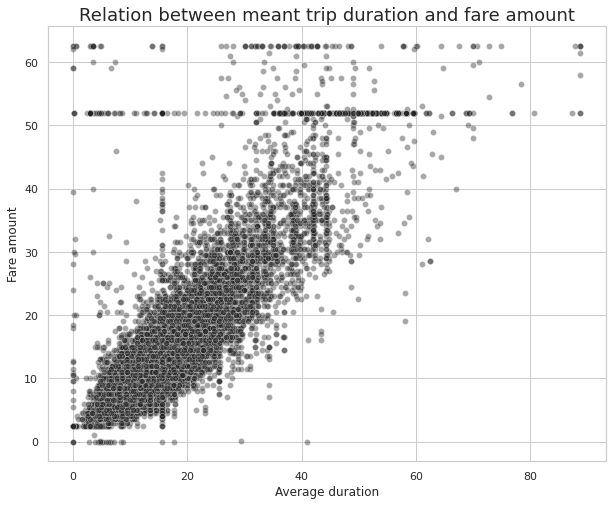

In [84]:
# Create a scatterplot to visualize the relationship between variables of interest
plt.figure(figsize=(10,8))
sns.set(style='whitegrid', palette='gray')
           
sns.scatterplot(data=df, 
            x='mean_duration', 
            y='fare_amount',
            alpha=0.4
           )
plt.title('Relation between meant trip duration and fare amount', fontsize=18)
plt.xlabel('Average duration')
plt.ylabel('Fare amount')

The `mean_duration` variable correlates with the target variable. But what are the horizontal lines around fare amounts of 52 dollars and 63 dollars? What are the values and how many are there?

You know what one of the lines represents. 62 dollars and 50 cents is the maximum that was imputed for outliers, so all former outliers will now have fare amounts of \$62.50. What is the other line?

Check the value of the rides in the second horizontal line in the scatter plot.

In [30]:
df1 = df[df['fare_amount'] > 50]
df1['fare_amount'].value_counts()

52.0    514
62.5     84
59.0      9
50.5      9
57.5      8
51.0      7
60.0      6
55.0      6
51.5      6
53.0      4
52.5      4
61.0      3
62.0      3
55.5      3
56.0      3
56.5      3
58.5      2
59.5      2
61.5      2
57.0      2
54.0      2
58.0      1
54.7      1
54.5      1
Name: fare_amount, dtype: int64

Examine the first 30 of these trips.

In [31]:
# Set pandas to display all columns
pd.set_option('display.max_columns', None)
df1.head(30)

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,duration,pickup_dropoff,mean_distance,mean_duration,day,month,rush_hour
11,18600059,2,2017-03-05 19:15:30,2017-03-05 19:52:18,2,18.90,2,N,236,132,1,52.0,0.0,0.5,14.58,5.54,0.3,72.92,36.800000,236 132,19.211667,40.500000,Sunday,March,0
21,85505540,2,2017-10-11 12:34:49,2017-10-11 13:22:38,1,12.30,5,N,138,265,1,62.5,0.0,0.0,12.00,16.26,0.3,96.81,47.816667,138 265,20.552000,39.376667,Wednesday,October,0
29,94052446,2,2017-11-06 20:30:50,2017-11-07 00:00:00,1,30.83,1,N,132,23,1,62.5,0.5,0.5,18.56,11.52,0.3,111.38,88.783333,132 23,30.830000,88.783333,Monday,November,0
110,47959795,1,2017-06-03 14:24:57,2017-06-03 15:31:48,1,18.00,2,N,132,163,1,52.0,0.0,0.5,0.00,0.00,0.3,52.80,66.850000,132 163,19.229000,52.941667,Saturday,June,0
156,104881101,1,2017-12-11 10:21:18,2017-12-11 11:14:57,1,15.60,1,N,138,88,1,51.5,0.0,0.5,11.60,5.76,0.3,69.66,53.650000,138 88,15.393333,64.316667,Monday,December,0
161,95729204,2,2017-11-11 20:16:16,2017-11-11 20:17:14,1,0.23,2,N,132,132,2,52.0,0.0,0.5,0.00,0.00,0.3,52.80,0.966667,132 132,2.255862,3.021839,Saturday,November,0
174,53109134,1,2017-06-22 14:22:05,2017-06-22 16:07:28,1,16.90,1,N,230,219,2,62.5,0.0,0.5,0.00,0.00,0.3,72.30,88.783333,230 219,16.900000,88.783333,Thursday,June,0
176,50046493,2,2017-06-13 20:05:03,2017-06-13 20:42:53,1,18.05,3,N,163,1,2,62.5,0.5,0.0,0.00,10.50,0.3,80.80,37.833333,163 1,18.050000,37.833333,Tuesday,June,0
220,95620783,2,2017-11-11 13:39:55,2017-11-11 14:53:05,1,13.61,1,N,132,181,1,55.0,0.0,0.5,11.16,0.00,0.3,66.96,73.166667,132 181,17.358571,42.697619,Saturday,November,0
242,67332929,2,2017-08-09 08:32:09,2017-08-09 09:31:11,1,15.89,1,N,138,87,1,53.0,0.0,0.5,10.00,5.76,0.3,69.56,59.033333,138 87,13.812500,44.284722,Wednesday,August,1


**Question:** What do you notice about the first 30 trips?

- Trips with a 52 dollars flat fare consistently correspond to Location 132 and RatecodeID 2.
- RatecodeID 2 maps to JFK Airport, matching NYC’s official 2017 flat-rate fare structure between Manhattan and JFK (further supported by frequent 5.54/5.76 dollars toll charges)
- Rather than relying solely on model estimates, JFK flat fares can be imputed deterministically post-prediction to ensure exact accuracy.

### Task 5. Isolate modeling variables

Drop features that are redundant, irrelevant, or that will not be available in a deployed environment.

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             22699 non-null  int64         
 1   VendorID               22699 non-null  int64         
 2   tpep_pickup_datetime   22699 non-null  datetime64[ns]
 3   tpep_dropoff_datetime  22699 non-null  datetime64[ns]
 4   passenger_count        22699 non-null  int64         
 5   trip_distance          22699 non-null  float64       
 6   RatecodeID             22699 non-null  int64         
 7   store_and_fwd_flag     22699 non-null  object        
 8   PULocationID           22699 non-null  string        
 9   DOLocationID           22699 non-null  string        
 10  payment_type           22699 non-null  int64         
 11  fare_amount            22699 non-null  float64       
 12  extra                  22699 non-null  float64       
 13  m

In [33]:
stay = ['VendorID', 'passenger_count', 'fare_amount', 'mean_distance', 'mean_duration', 'rush_hour']
df2 = df[stay]
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   VendorID         22699 non-null  int64  
 1   passenger_count  22699 non-null  int64  
 2   fare_amount      22699 non-null  float64
 3   mean_distance    22699 non-null  float64
 4   mean_duration    22699 non-null  float64
 5   rush_hour        22699 non-null  int64  
dtypes: float64(3), int64(3)
memory usage: 1.0 MB


### Task 6. Pair plot

Create a pairplot to visualize pairwise relationships between `fare_amount`, `mean_duration`, and `mean_distance`.

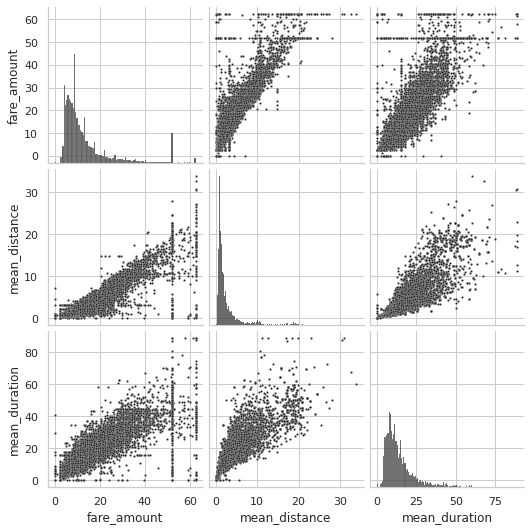

In [85]:
# Create a pairplot to visualize pairwise relationships between variables in the data
sns.pairplot(df2[['fare_amount', 'mean_distance', 'mean_duration']], plot_kws={'s': 5} )

These variables all show linear correlation with each other. Investigate this further.

### Task 7. Identify correlations

Next, code a correlation matrix to help determine most correlated variables.

In [35]:
# Correlation matrix to help determine most correlated variables
corr_matrix = df2.corr()
corr_matrix

,VendorID,passenger_count,fare_amount,mean_distance,mean_duration,rush_hour
VendorID,1.000000,0.266463,0.001045,0.004741,0.001876,-0.002874
passenger_count,0.266463,1.000000,0.014942,0.013428,0.015852,-0.022035
fare_amount,0.001045,0.014942,1.000000,0.910185,0.859105,-0.020075
mean_distance,0.004741,0.013428,0.910185,1.000000,0.874864,-0.039725
mean_duration,0.001876,0.015852,0.859105,0.874864,1.000000,-0.021583
rush_hour,-0.002874,-0.022035,-0.020075,-0.039725,-0.021583,1.000000


Visualize a correlation heatmap of the data.

Text(0.5, 1.0, "Variable's Correlation Matrix")

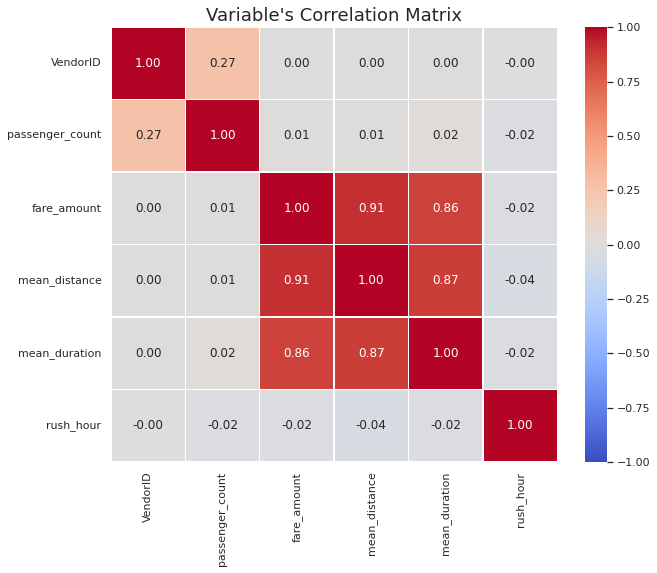

In [86]:
# Create correlation heatmap
plt.figure(figsize=(10,8))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, fmt='.2f')
plt.title("Variable's Correlation Matrix", fontsize=18)

**Question:** Which variable(s) are correlated with the target variable of `fare_amount`? 
- Mean trip distance and mean duration both show strong positive correlations with fare_amount.
- Distance and duration are also strongly correlated with each other, which should be accounted for in linear modeling to avoid multicollinearity.

Try modeling with both variables even though they are correlated.

<img src="images/Construct.png" width="100" height="100" align=left>

## PACE: **Construct**

After analysis and deriving variables with close relationships, it is time to begin constructing the model. Consider the questions in your PACE Strategy Document to reflect on the Construct stage.


### Task 8a. Split data into outcome variable and features

In [37]:
df2.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   VendorID         22699 non-null  int64  
 1   passenger_count  22699 non-null  int64  
 2   fare_amount      22699 non-null  float64
 3   mean_distance    22699 non-null  float64
 4   mean_duration    22699 non-null  float64
 5   rush_hour        22699 non-null  int64  
dtypes: float64(3), int64(3)
memory usage: 1.0 MB


Set your X and y variables. X represents the features and y represents the outcome (target) variable.

In [38]:
# Remove the target column from the features
X = df2.drop(columns='fare_amount')

# Set y variable
y = df2[['fare_amount']]

# Display first few rows
X.head()

,VendorID,passenger_count,mean_distance,mean_duration,rush_hour
0,2,6,3.521667,22.847222,0
1,1,1,3.108889,24.470370,0
2,1,1,0.881429,7.250000,1
3,2,1,3.700000,30.250000,0
4,2,1,4.435000,14.616667,0


### Task 8b. Pre-process data


Dummy encode categorical variables

In [39]:
# Convert VendorID to string
X['VendorID'] = X['VendorID'].astype('string')

# Get dummies
X = pd.get_dummies(X, drop_first=True)
X.head()

,VendorID,passenger_count,mean_distance,mean_duration,rush_hour
0,2,6,3.521667,22.847222,0
1,1,1,3.108889,24.470370,0
2,1,1,0.881429,7.250000,1
3,2,1,3.700000,30.250000,0
4,2,1,4.435000,14.616667,0


### Split data into training and test sets

Create training and testing sets. The test set should contain 20% of the total samples. Set `random_state=0`.

In [40]:
# Create training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


### Standardize the data

Use `StandardScaler()`, `fit()`, and `transform()` to standardize the `X_train` variables. Assign the results to a variable called `X_train_scaled`.

In [41]:
# Standardize the X variables
X_train_scaled = StandardScaler().fit_transform(X_train)
X_train_scaled


array([[ 0.89286563, -0.50301524,  0.8694684 ,  0.17616665, -0.64893329],
       [ 0.89286563, -0.50301524, -0.60011281, -0.69829589,  1.54099045],
       [-1.11998936,  0.27331093, -0.47829156, -0.57301906, -0.64893329],
       ...,
       [-1.11998936, -0.50301524, -0.45121122, -0.6788917 , -0.64893329],
       [-1.11998936, -0.50301524, -0.58944763, -0.85743597,  1.54099045],
       [ 0.89286563,  1.82596329,  0.83673851,  1.13212101, -0.64893329]])

### Fit the model

Instantiate your model and fit it to the training data.

In [42]:
# Fit your model to the training data
model = LinearRegression().fit(X_train_scaled, y_train)
model

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

### Task 8c. Evaluate model

### Train data

Evaluate your model performance by calculating the residual sum of squares and the explained variance score (R^2). Calculate the Mean Absolute Error, Mean Squared Error, and the Root Mean Squared Error.

In [43]:
# Evaluate the model performance on the training data
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

y_pred_train = model.predict(X_train_scaled)

rss_train = np.sum((y_train - y_pred_train) ** 2)
r2_train = r2_score(y_train, y_pred_train)

mae_train = mean_absolute_error(y_train, y_pred_train)
mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)

print('Residual Sum of Squares (RSS): ', round(rss_train, 4))
print('R^2 Score: ', round(r2_train, 4))
print('Mean Absolute Error (MAE): ', round(mae_train, 4))
print('Mean Squared Error (MSE): ', round(mse_train, 4))
print('Root Mean Squared Error (RMSE): ', round(rmse_train, 4))

Residual Sum of Squares (RSS):  fare_amount    324859.6609
dtype: float64
R^2 Score:  0.8398
Mean Absolute Error (MAE):  2.1867
Mean Squared Error (MSE):  17.8897
Root Mean Squared Error (RMSE):  4.2296


### Test data

Calculate the same metrics on the test data. Remember to scale the `X_test` data using the scaler that was fit to the training data. Do not refit the scaler to the testing data, just transform it. Call the results `X_test_scaled`.

In [44]:
# Scale the X_test data
X_test_scaled = StandardScaler().fit(X_train).transform(X_test)
X_test_scaled

array([[ 0.89286563, -0.50301524, -0.01228033, -0.1109662 , -0.64893329],
       [ 0.89286563, -0.50301524,  0.1705781 ,  0.83266676, -0.64893329],
       [ 0.89286563,  0.27331093, -0.56800902, -0.71163492, -0.64893329],
       ...,
       [ 0.89286563, -0.50301524, -0.5294519 , -0.64990563, -0.64893329],
       [-1.11998936, -0.50301524, -0.53660633, -0.83261981, -0.64893329],
       [ 0.89286563, -0.50301524, -0.29519336, -0.17972406,  1.54099045]])

In [45]:
# Evaluate the model performance on the testing data
y_pred_test = model.predict(X_test_scaled)

rss_test = np.sum((y_test - y_pred_test) ** 2)
r2_test = r2_score(y_test, y_pred_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
mse_test = mean_squared_error(y_test, y_pred_test)
rmse_test = np.sqrt(mse_test)

print('Residual Sum of Squares (RSS): ', round(rss_test, 4))
print('R^2 Score: ', round(r2_test, 4))
print('Mean Absolute Error (MAE): ', round(mae_test, 4))
print('Mean Squared Error (MSE): ', round(mse_test, 4))
print('Root Mean Squared Error (RMSE): ', round(rmse_test, 4))



Residual Sum of Squares (RSS):  fare_amount    65042.1019
dtype: float64
R^2 Score:  0.8683
Mean Absolute Error (MAE):  2.1337
Mean Squared Error (MSE):  14.3265
Root Mean Squared Error (RMSE):  3.785


<img src="images/Execute.png" width="100" height="100" align=left>

## PACE: **Execute**

Consider the questions in your PACE Strategy Document to reflect on the Execute stage.

### Task 9a. Results

Use the code cell below to get `actual`,`predicted`, and `residual` for the testing set, and store them as columns in a `results` dataframe.

In [46]:
# Create a `results` dataframe
actuals = y_test['fare_amount']
preds = y_pred_test.ravel()

results = pd.DataFrame(
    {'actual': actuals, 'predicted': preds, 'residual': actuals - preds}
)

results.head(10)


,actual,predicted,residual
5818,14.0,12.356503,1.643497
18134,28.0,16.314595,11.685405
4655,5.5,6.726789,-1.226789
7378,15.5,16.227206,-0.727206
13914,9.5,10.536408,-1.036408
308,23.5,20.917749,2.582251
3061,39.5,37.033384,2.466616
12401,57.5,37.697354,19.802646
5662,24.5,22.981548,1.518452
21767,8.0,8.691078,-0.691078


### Task 9b. Visualize model results

Create a scatterplot to visualize `actual` vs. `predicted`.

Text(0, 0.5, 'Predicted')

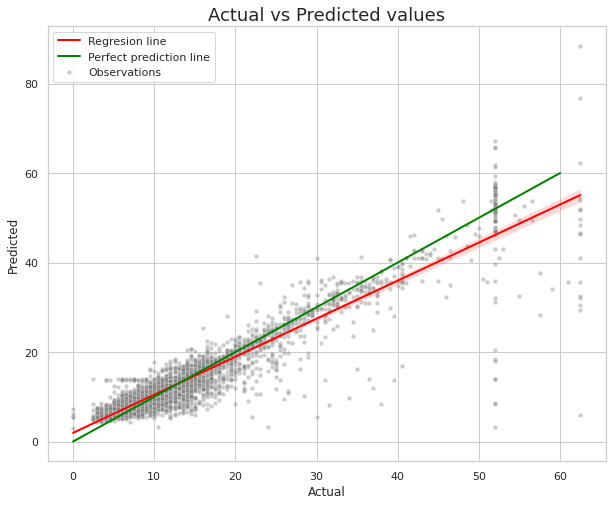

In [87]:
# Create a scatterplot to visualize `predicted` over `actual`
plt.figure(figsize=(10,8))

sns.scatterplot(
    data=results,
    x='actual',
    y='predicted',
    alpha=0.4,
    s=20,
    label='Observations', 
)

sns.regplot(
    data=results,
    x='actual',
    y='predicted',
    scatter=False,  
    color='red',
    line_kws={'linewidth': 2},
    label='Regresion line',  
)

plt.plot([0, 60], [0, 60], c='green', linewidth=2, label='Perfect prediction line')

plt.legend()

plt.title('Actual vs Predicted values', fontsize=18)
plt.xlabel('Actual')
plt.ylabel('Predicted')



Visualize the distribution of the `residuals` using a histogram.

Text(0.5, 0, 'Residual value')

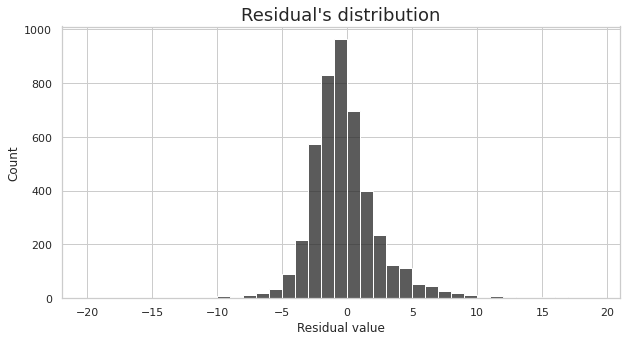

In [95]:
# Visualize the distribution of the `residuals`
plt.figure(figsize=(10, 5))

sns.histplot(data=results, x='residual', bins=range(-20,20,1))

plt.title("Residual's distribution", fontsize=18)
plt.xlabel('Residual value')



In [90]:
# Calculate residual mean
results['residual'].mean()

-0.015442621528680771

Create a scatterplot of `residuals` over `predicted`.

Text(0, 0.5, 'Residuals')

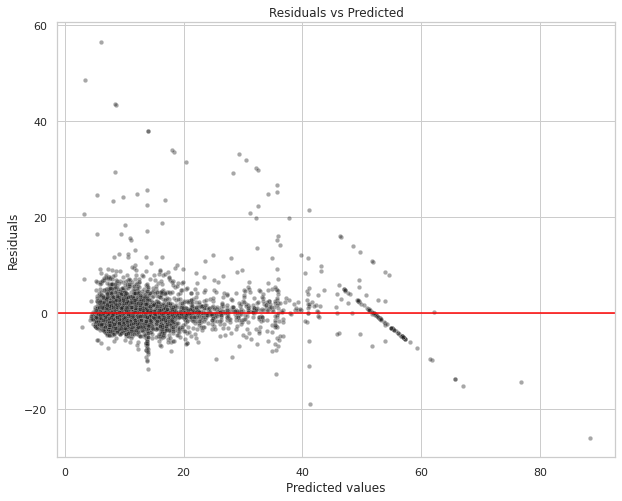

In [96]:
# Create a scatterplot of `residuals` over `predicted`
plt.figure(figsize=(10,8))
sns.scatterplot(
    data=results,
    x='predicted',
    y='residual',
    alpha=0.4,
    s=20,
)
plt.axhline(y=0, color='red')

plt.title('Residuals vs Predicted')
plt.xlabel('Predicted values')
plt.ylabel('Residuals')


### Task 9c. Coefficients

Use the `coef_` attribute to get the model's coefficients. The coefficients are output in the order of the features that were used to train the model. Which feature had the greatest effect on trip fare?

In [101]:
# Output the model's coefficients
coefficients = pd.DataFrame(model.coef_, columns=X.columns)
coefficients

,VendorID,passenger_count,mean_distance,mean_duration,rush_hour
0,-0.054373,0.030825,7.133867,2.812115,0.110233


What do these coefficients mean? How should they be interpreted?

Each coefficient represents the estimated change in the fare_amount for a one-unit increase in that feature:
* mean_distance has the largest positive impact. For every unit increase in mean distance, the estimated fare increases by approximately 7.13, holding everything else constant.
* mean_duration shows a strong positive effect. Each additional unit of mean duration increases the estimated fare by about 2.81.
* rush_hour has a minor positive effect; traveling during rush hour slightly increases the estimated fare by 0.11 compared to other times.
* Last two has very close to zero values, which means their influence is not significant.


### Task 9d. Conclusion

1. What are the key takeaways from this notebook?



2. What results can be presented from this notebook?



**Takeaways**
* EDA (Exploratory Data Analysis) continues to be a crucial step before modeling, as it is necessary to identify outliers that can negatively impact performance and select the appropriate independent and dependent features.

* Multiple linear regression is highly effective for quantifying the influence that various independent variables have on a dependent variable.

* Model evaluation requires checking metrics on both the training and testing data to accurately assess performance and generalizability.

**Results to present to stakeholders**

**1. Exploratory Data Analysis (EDA) & Data Cleaning**
* **Handling Anomalies:** Identified and addressed data recording errors, specifically negative values and extreme upper bounds in fare_amount, as well as negative and unrealistically long trip times in duration.
* **Feature Consistency:** Trip distances proved reliable and served as a logical baseline explaining trip durations.
* **Multicollinearity Considerations:** Both mean_distance and mean_duration show strong positive correlations with fare_amount and with each other, requiring proper handling in linear modeling to avoid multicollinearity.
* **Domain-Specific Insights (JFK Flat Fares):** Trips with a flat fare of \$52 dollars consistently map to Location 132 and RatecodeID 2, aligning with NYC's official JFK-Manhattan flat-rate structure. Rather than relying solely on model estimates, these can be imputed deterministically post-prediction for exact accuracy.

**2. Model Performance Metrics**
The model demonstrates strong performance and excellent generalizability, performing slightly better on the test set than the training set:

**$R^2$ (0.8683):** Indicates that the model successfully captures 86.8% of the variability in trip fares on the test set.

**MAE (\$2.13)** & **RMSE (\$3.79):** Show a low average prediction error, with RMSE pointing to a few larger discrepancies in certain trips.

The test set performing slightly better than the training set confirms that the model avoids overfitting and generalizes robustly to unseen data.


**3. Feature Impact & Coefficient Interpretation**
Each coefficient represents the estimated change in fare_amount for a one-unit increase in that feature, holding all other variables constant:
* **mean_distance (+7.13):** The primary driver of the fare; every unit increase in mean distance increases the estimated fare by roughly \$7.13.
* **mean_duration (+2.81):** Displays a strong positive effect, where each additional unit of duration increases the estimated fare by about \$2.81.
* **rush_hour (+0.11):** Exhibits a minor positive effect, slightly increasing the estimated fare by \$11 cents compared to non-rush hour times.
* **Remaining Features:** Values close to zero indicate that their individual influence on the prediction is statistically negligible.

**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged. 